# Employee Workforce Segmentation
**Techniques:** K-Means, Hierarchical (Ward) clustering, PCA  |  **Dataset:** `data/employee_data.csv` (1,470 employees, 16 columns)

**Business question:** Which groups of employees exist in our workforce, which of them are most likely to leave, and what should HR do differently for each group?

**Workflow:** EDA -> scaling -> PCA (dimension reduction) -> K-Means and Hierarchical clustering on the PCA space -> segment profiling -> high-risk clusters, department segments, performance groups, retention-risk groups -> export for the dashboard.

> `Attrition` and `Department` are deliberately **not** used to form the clusters. They are used afterwards to *interpret* the segments, so the segmentation is not biased by the outcome we want to explain.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); pd.set_option('display.width', 220, 'display.max_columns', 40)
SEED = 42
df = pd.read_csv('data/employee_data.csv')
print('Shape:', df.shape, '| missing values:', int(df.isna().sum().sum()), '| duplicate rows:', int(df.duplicated().sum()))
df.head()

Shape: (1470, 16) | missing values: 0 | duplicate rows: 0


   EmployeeID  Age              Department  JobLevel  MonthlyIncome  TotalWorkingYears  YearsAtCompany  YearsSinceLastPromotion  DistanceFromHome OverTime  JobSatisfaction  EnvironmentSatisfaction  WorkLifeBalance  PerformanceRating  TrainingTimesLastYear Attrition
0           1   25                   Sales         2           7180                  5               2                        1                 8       No                3                        3                3                  2                      1        No
1           2   29  Research & Development         1           6700                  7               1                        1                 3      Yes                2                        1                2                  2                      2       Yes
2           3   57  Research & Development         3          10720                 36              23                       13                22       No                2                        4      

## 1. Exploratory data analysis

                            mean      std     min     50%      max
EmployeeID                735.50   424.50     1.0   735.5   1470.0
Age                        36.52     9.56    19.0    36.0     60.0
JobLevel                    2.40     1.13     1.0     2.0      5.0
MonthlyIncome            9371.40  3293.13  2800.0  9025.0  17930.0
TotalWorkingYears          15.65     9.73     0.0    15.0     40.0
YearsAtCompany              7.61     6.41     0.0     6.0     28.0
YearsSinceLastPromotion     3.11     3.49     0.0     2.0     15.0
DistanceFromHome            9.63     6.54     1.0     8.0     29.0
JobSatisfaction             2.68     0.94     1.0     3.0      4.0
EnvironmentSatisfaction     2.74     0.85     1.0     3.0      4.0
WorkLifeBalance             2.68     0.92     1.0     3.0      4.0
PerformanceRating           3.13     0.87     2.0     3.0      5.0
TrainingTimesLastYear       2.49     1.62     0.0     2.0      6.0

Overall attrition rate: 16.1%


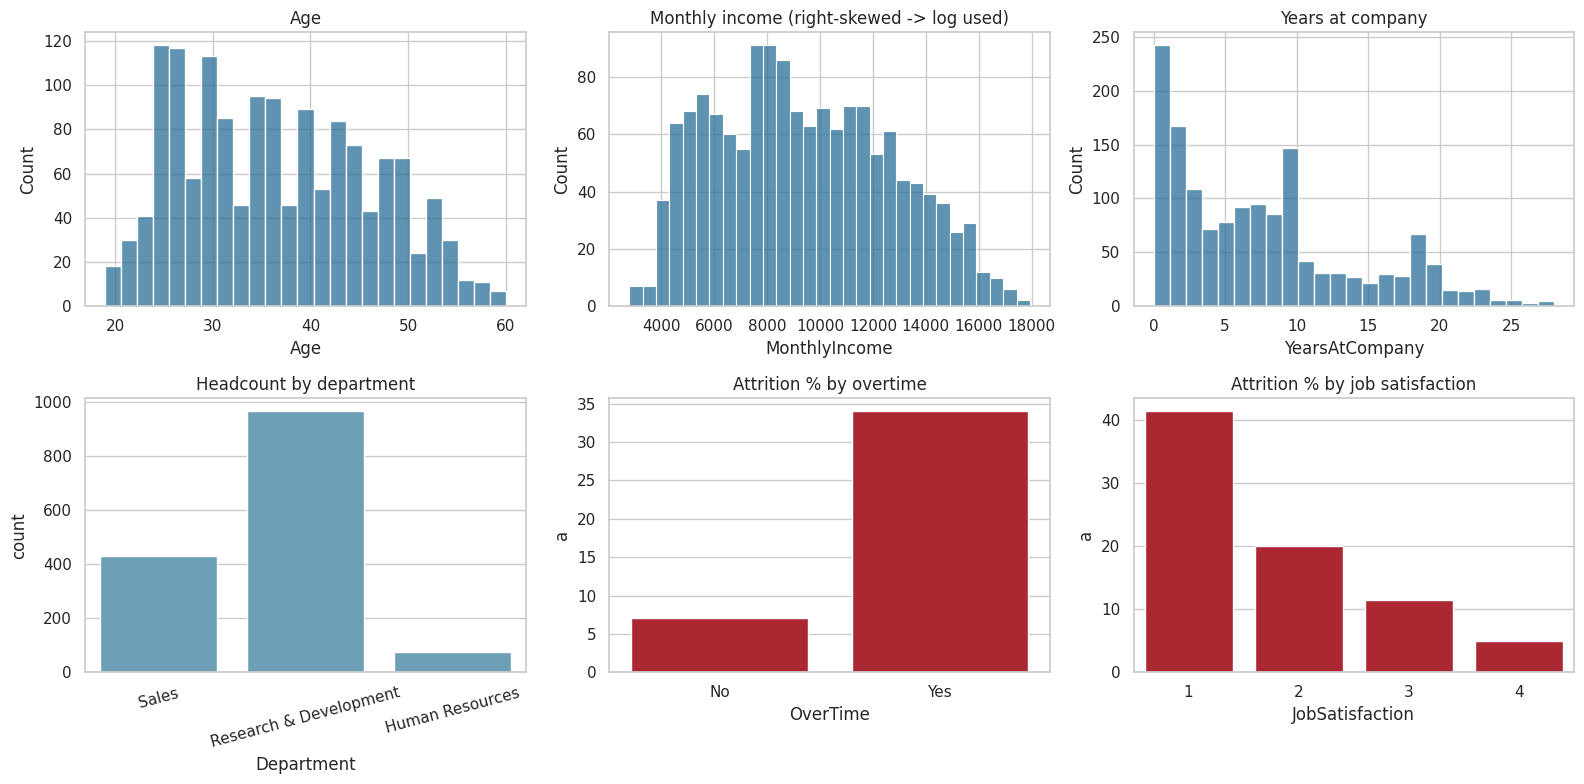

In [2]:
print(df.describe().round(2).T[['mean','std','min','50%','max']])
print('\nOverall attrition rate: %.1f%%' % (100*(df.Attrition=='Yes').mean()))
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(df.Age, bins=25, ax=ax[0,0], color='#2a6f97'); ax[0,0].set_title('Age')
sns.histplot(df.MonthlyIncome, bins=30, ax=ax[0,1], color='#2a6f97'); ax[0,1].set_title('Monthly income (right-skewed -> log used)')
sns.histplot(df.YearsAtCompany, bins=25, ax=ax[0,2], color='#2a6f97'); ax[0,2].set_title('Years at company')
sns.countplot(data=df, x='Department', ax=ax[1,0], color='#61a5c2'); ax[1,0].set_title('Headcount by department'); ax[1,0].tick_params(axis='x', rotation=15)
sns.barplot(data=df.assign(a=(df.Attrition=='Yes')*100), x='OverTime', y='a', ax=ax[1,1], color='#c1121f', errorbar=None); ax[1,1].set_title('Attrition % by overtime')
sns.barplot(data=df.assign(a=(df.Attrition=='Yes')*100), x='JobSatisfaction', y='a', ax=ax[1,2], color='#c1121f', errorbar=None); ax[1,2].set_title('Attrition % by job satisfaction')
plt.tight_layout(); plt.savefig('figures/01_eda.png', dpi=130); plt.show()

**EDA findings.** Income is right-skewed (so we use `log1p`); overtime and low satisfaction show clearly higher attrition. Several variables (age, tenure, level, income) move together, which is exactly the situation where PCA helps.

## 2. Preprocessing
* **Clustering features (12):** Age, JobLevel, MonthlyIncome (log), YearsAtCompany, YearsSinceLastPromotion, DistanceFromHome, OverTime (0/1), JobSatisfaction, EnvironmentSatisfaction, WorkLifeBalance, PerformanceRating, TrainingTimesLastYear.
* `TotalWorkingYears` is dropped (almost a copy of Age). `EmployeeID`, `Attrition` and `Department` are kept out of the clustering.
* All features are **standardised** (mean 0, std 1) because both K-Means and PCA are distance/variance based.

In [3]:
FEATURES = ['Age','JobLevel','MonthlyIncome','YearsAtCompany','YearsSinceLastPromotion','DistanceFromHome',
            'OverTime','JobSatisfaction','EnvironmentSatisfaction','WorkLifeBalance','PerformanceRating','TrainingTimesLastYear']
X = df[FEATURES].copy()
X['OverTime'] = (X['OverTime'] == 'Yes').astype(int)
X['MonthlyIncome'] = np.log1p(X['MonthlyIncome'])
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
print('Scaled matrix:', Xs.shape, '| mean ~', Xs.mean().round(3), '| std ~', Xs.std().round(3))

Scaled matrix: (1470, 12) | mean ~ 0.0 | std ~ 1.0


## 3. PCA - reducing the feature dimensions
We fit PCA on all 12 standardised features, inspect the explained variance, and keep enough components to retain **at least 85 %** of the variance. Those components are the input to both clustering algorithms.

Component  Eigenvalue  Variance_%  Cumulative_%
      PC1       3.385       28.19         28.19
      PC2       2.365       19.69         47.89
      PC3       1.259       10.48         58.37
      PC4       0.998        8.31         66.68
      PC5       0.849        7.07         73.75
      PC6       0.775        6.45         80.20
      PC7       0.705        5.87         86.08
      PC8       0.628        5.23         91.31
      PC9       0.524        4.36         95.67
     PC10       0.278        2.31         97.99
     PC11       0.178        1.48         99.47
     PC12       0.064        0.53        100.00

Components needed for >=85% variance: 7 (from 12 features); for >=70%: 5
PC1 is driven by: YearsAtCompany (+0.47), Age (+0.47), MonthlyIncome (+0.45), JobLevel (+0.41)
PC2 is driven by: PerformanceRating (+0.45), JobSatisfaction (+0.43), EnvironmentSatisfaction (+0.35), WorkLifeBalance (+0.33)
PC3 is driven by: OverTime (+0.53), WorkLifeBalance (-0.42), JobLevel (+0.36), M

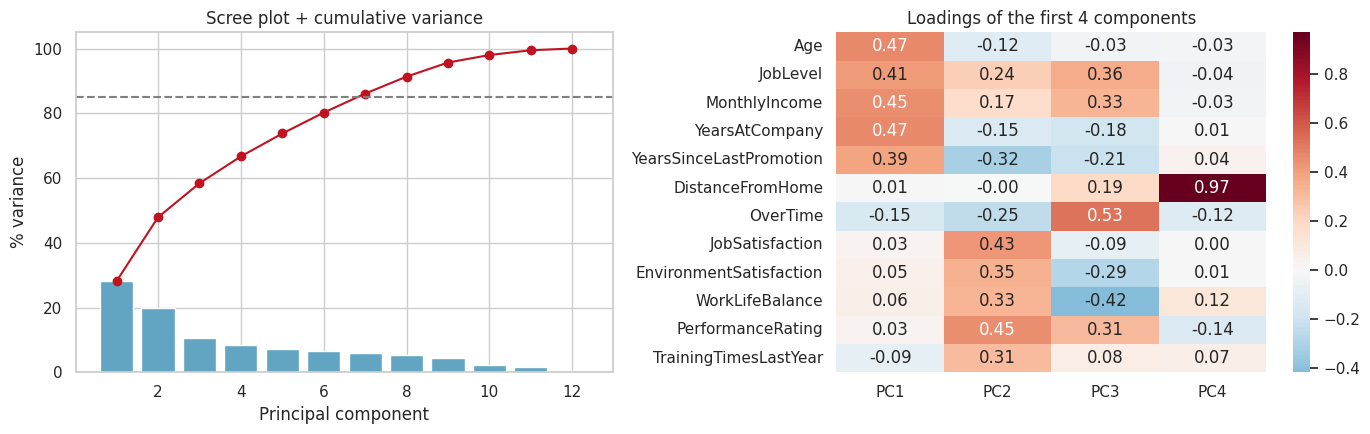

In [4]:
pca_full = PCA(random_state=SEED).fit(Xs)
evr = pca_full.explained_variance_ratio_; cum = evr.cumsum()
N_PC = int(np.argmax(cum >= 0.85) + 1)
pca_table = pd.DataFrame({'Component': [f'PC{i+1}' for i in range(len(evr))], 'Eigenvalue': pca_full.explained_variance_.round(3),
                          'Variance_%': (evr*100).round(2), 'Cumulative_%': (cum*100).round(2)})
print(pca_table.to_string(index=False))
print(f'\nComponents needed for >=85% variance: {N_PC} (from {Xs.shape[1]} features); for >=70%: {int(np.argmax(cum>=0.70)+1)}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(range(1, len(evr)+1), evr*100, color='#61a5c2'); ax[0].plot(range(1, len(evr)+1), cum*100, 'o-', color='#c1121f')
ax[0].axhline(85, ls='--', color='grey'); ax[0].set_xlabel('Principal component'); ax[0].set_ylabel('% variance'); ax[0].set_title('Scree plot + cumulative variance')
load = pd.DataFrame(pca_full.components_[:4].T, index=FEATURES, columns=['PC1','PC2','PC3','PC4'])
sns.heatmap(load, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[1]); ax[1].set_title('Loadings of the first 4 components')
plt.tight_layout(); plt.savefig('figures/02_pca_scree_loadings.png', dpi=130); plt.show()
for pc in ['PC1','PC2','PC3']:
    top = load[pc].abs().sort_values(ascending=False).index[:4]
    print(pc, 'is driven by:', ', '.join(f"{t} ({load.loc[t,pc]:+.2f})" for t in top))

In [5]:
pca = PCA(n_components=N_PC, random_state=SEED)
Xp = pca.fit_transform(Xs)
df['PC1'], df['PC2'] = Xp[:, 0], Xp[:, 1]
print('Reduced data:', Xp.shape, '| variance retained: %.1f%%' % (100*pca.explained_variance_ratio_.sum()))

Reduced data: (1470, 7) | variance retained: 86.1%


## 4. K-Means - choosing the number of clusters
We test k = 2...8 with four criteria: **inertia** (elbow), **silhouette** (higher is better), **Calinski-Harabasz** (higher is better) and **Davies-Bouldin** (lower is better). A segmentation HR can act on needs at least 3 groups, so we look only at k = 3...6. **Selection rule (stated up-front):** take the *largest* k whose silhouette is within 0.01 of the best silhouette - when scores are practically tied, the finer segmentation is preferred because it separates groups HR would treat differently. The result is cross-checked against Davies-Bouldin and Calinski-Harabasz.

     Inertia  Silhouette  Calinski_Harabasz  Davies_Bouldin
k                                                          
2  11381.955       0.233            490.381           1.680
3   8863.389       0.271            523.078           1.367
4   7471.475       0.268            504.436           1.371
5   7103.897       0.252            416.583           1.484
6   6775.166       0.207            363.404           1.799
7   6551.663       0.199            321.272           1.765
8   6315.634       0.152            293.278           2.006

Best silhouette at k = 3 | selected k = 4 (largest k within 0.01 of the best)


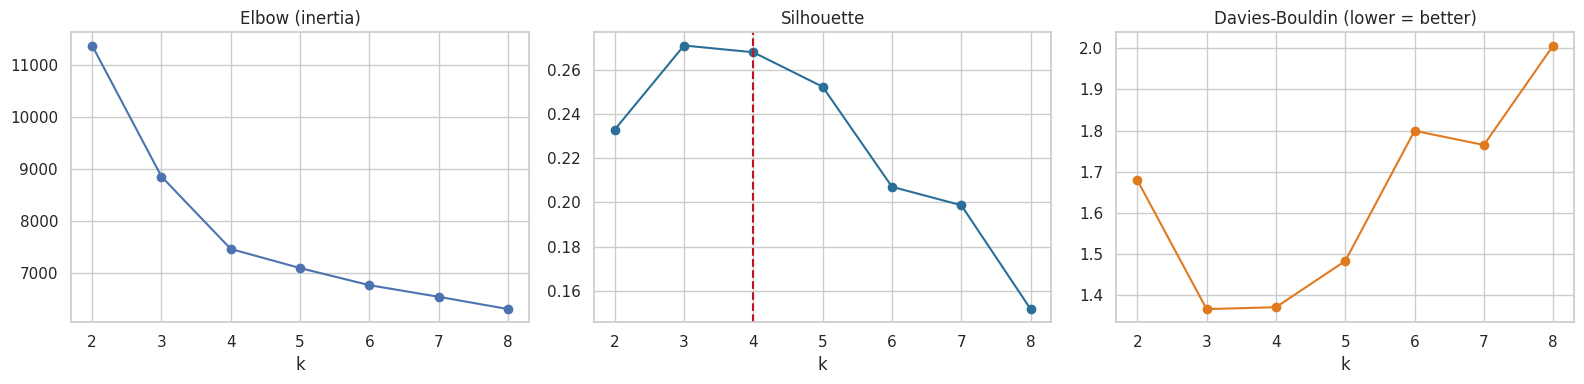

In [6]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xp)
    rows.append({'k': k, 'Inertia': km.inertia_, 'Silhouette': silhouette_score(Xp, km.labels_),
                 'Calinski_Harabasz': calinski_harabasz_score(Xp, km.labels_), 'Davies_Bouldin': davies_bouldin_score(Xp, km.labels_)})
kres = pd.DataFrame(rows).set_index('k'); print(kres.round(3))
cand = kres.loc[3:6, 'Silhouette']; K = int(cand[cand >= cand.max() - 0.01].index.max())
print('\nBest silhouette at k =', int(cand.idxmax()), '| selected k =', K, '(largest k within 0.01 of the best)')
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(kres.index, kres.Inertia, 'o-'); ax[0].set_title('Elbow (inertia)'); ax[0].set_xlabel('k')
ax[1].plot(kres.index, kres.Silhouette, 'o-', color='#2a6f97'); ax[1].axvline(K, ls='--', color='#c1121f'); ax[1].set_title('Silhouette'); ax[1].set_xlabel('k')
ax[2].plot(kres.index, kres.Davies_Bouldin, 'o-', color='#e07a1f'); ax[2].set_title('Davies-Bouldin (lower = better)'); ax[2].set_xlabel('k')
plt.tight_layout(); plt.savefig('figures/03_kmeans_selection.png', dpi=130); plt.show()

In [7]:
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Xp)
km_labels = km.labels_
# stability: re-run with 10 different seeds and compare with the final solution
aris = [adjusted_rand_score(km_labels, KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(Xp)) for s in range(10)]
print('K-Means stability over 10 seeds (ARI vs final): mean %.3f, min %.3f' % (np.mean(aris), np.min(aris)))
# does PCA change the answer? compare with K-Means on the full 12-D standardised data
km_full = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Xs)
print('ARI  K-Means(PCA space) vs K-Means(12-D):  %.3f' % adjusted_rand_score(km_labels, km_full.labels_))
print('Segment sizes:', np.bincount(km_labels))

K-Means stability over 10 seeds (ARI vs final): mean 1.000, min 1.000
ARI  K-Means(PCA space) vs K-Means(12-D):  0.989
Segment sizes: [314 429 301 426]


## 5. Hierarchical clustering (Ward linkage)
Ward linkage merges the pair of clusters that increases within-cluster variance the least. The dendrogram shows how groups join; we cut it at the same k as K-Means so the two methods can be compared directly.

                     Silhouette  Calinski_Harabasz  Davies_Bouldin
K-Means                   0.268            504.436           1.371
Hierarchical (Ward)       0.233            434.742           1.624

Agreement between the two methods (Adjusted Rand Index): 0.738

Cross-tab (rows = K-Means, columns = Hierarchical):
col_0    0    1    2    3
row_0                    
0      247   20    2   45
1        4  417    1    7
2        3    5  293    0
3       56   21    0  349


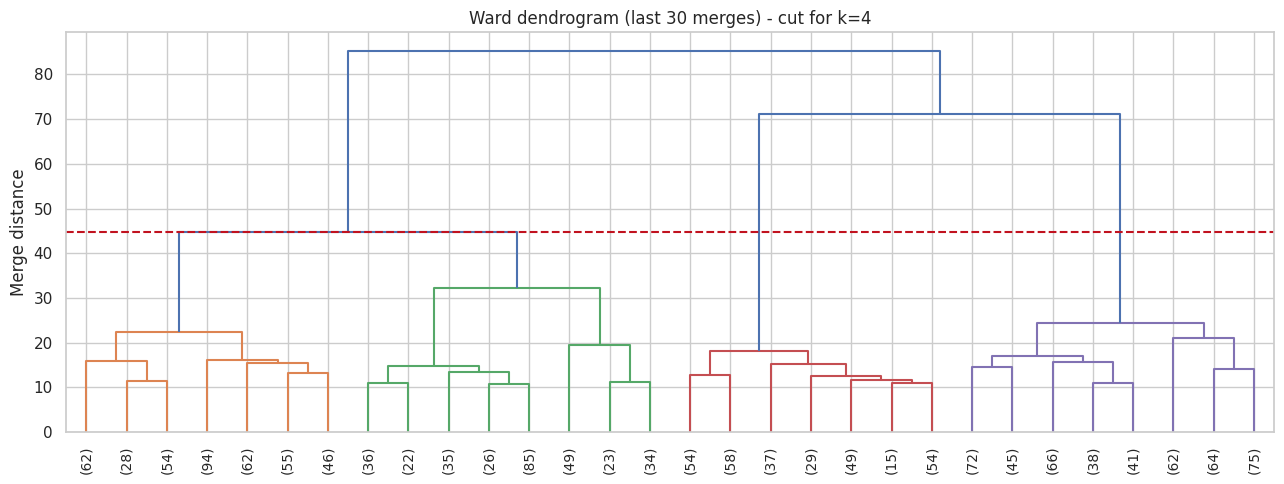

In [8]:
Z = linkage(Xp, method='ward')
hc = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(Xp); hc_labels = hc.labels_
fig, ax = plt.subplots(figsize=(13, 5))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True, leaf_rotation=90, ax=ax, color_threshold=Z[-(K-1), 2])
ax.axhline(Z[-(K-1), 2], ls='--', color='#c1121f'); ax.set_title(f'Ward dendrogram (last 30 merges) - cut for k={K}'); ax.set_ylabel('Merge distance')
plt.tight_layout(); plt.savefig('figures/04_dendrogram.png', dpi=130); plt.show()
cmp = pd.DataFrame({'Silhouette': [silhouette_score(Xp, km_labels), silhouette_score(Xp, hc_labels)],
                    'Calinski_Harabasz': [calinski_harabasz_score(Xp, km_labels), calinski_harabasz_score(Xp, hc_labels)],
                    'Davies_Bouldin': [davies_bouldin_score(Xp, km_labels), davies_bouldin_score(Xp, hc_labels)]}, index=['K-Means', 'Hierarchical (Ward)'])
print(cmp.round(3)); ari = adjusted_rand_score(km_labels, hc_labels)
print('\nAgreement between the two methods (Adjusted Rand Index): %.3f' % ari)
print('\nCross-tab (rows = K-Means, columns = Hierarchical):'); print(pd.crosstab(km_labels, hc_labels))

**Reading the comparison.** A high ARI means both algorithms discover essentially the same groups - evidence that the segments are real structure in the data and not an artefact of one algorithm. We use **K-Means** as the final segmentation (best/equal quality metrics, assigns new employees easily with `predict`) and keep the hierarchical result as validation.

## 6. Visualising the employee groups in PCA space

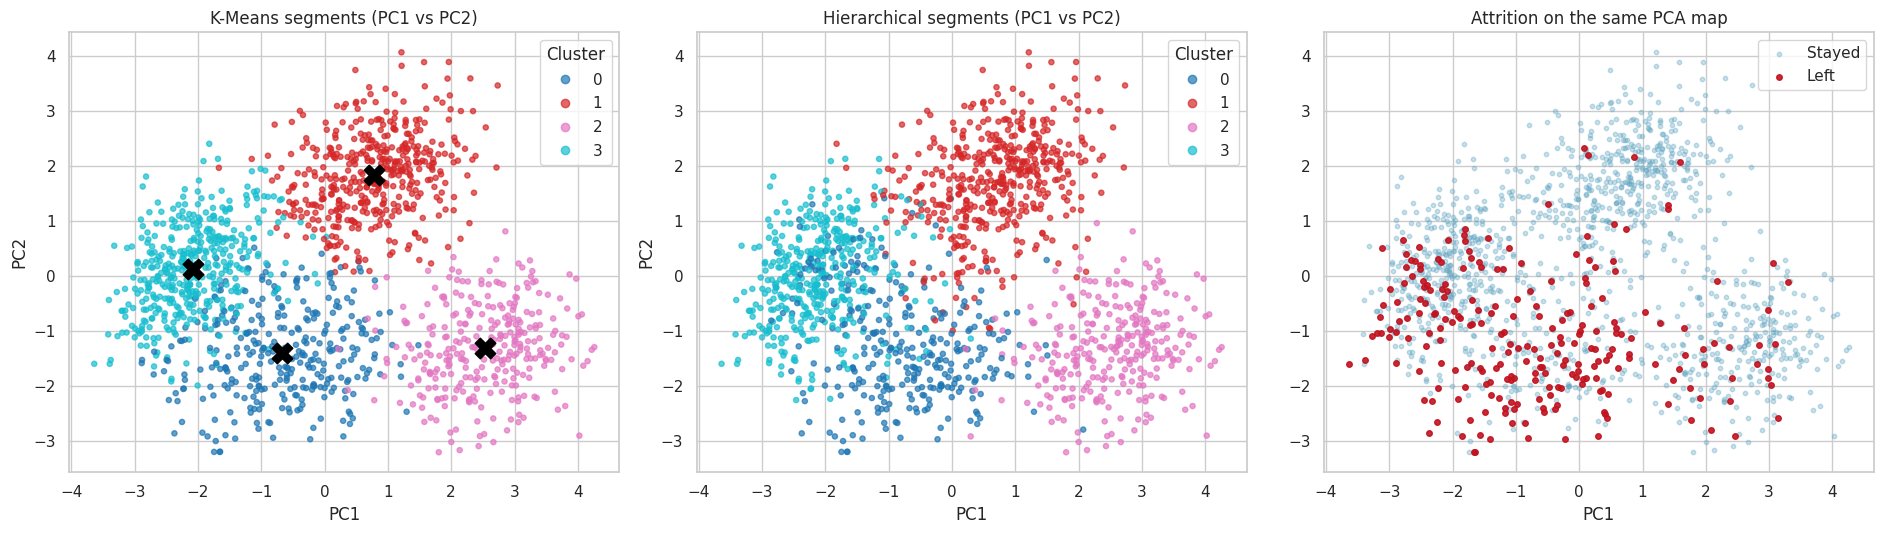

In [9]:
cent = km.cluster_centers_
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
for a, labs, t in [(ax[0], km_labels, 'K-Means segments'), (ax[1], hc_labels, 'Hierarchical segments')]:
    sc = a.scatter(df.PC1, df.PC2, c=labs, cmap='tab10', s=14, alpha=.7); a.set_title(t + ' (PC1 vs PC2)'); a.set_xlabel('PC1'); a.set_ylabel('PC2')
    a.legend(*sc.legend_elements(), title='Cluster', loc='best')
ax[0].scatter(cent[:, 0], cent[:, 1], marker='X', s=220, c='black', label='centroids')
att = (df.Attrition == 'Yes')
ax[2].scatter(df.PC1[~att], df.PC2[~att], s=10, alpha=.35, c='#61a5c2', label='Stayed'); ax[2].scatter(df.PC1[att], df.PC2[att], s=16, alpha=.9, c='#c1121f', label='Left')
ax[2].set_title('Attrition on the same PCA map'); ax[2].set_xlabel('PC1'); ax[2].legend()
plt.tight_layout(); plt.savefig('figures/05_pca_clusters.png', dpi=130); plt.show()

## 7. Segment profiling and naming
We attach the K-Means labels to the original data and compare the segments on the *original* (interpretable) variables. Segment names are assigned by a simple rule set based on each segment's profile (overtime/satisfaction, age/tenure, promotion gap).

In [10]:
df['Cluster'] = km_labels
df['OT'] = (df.OverTime == 'Yes').astype(int); df['Left'] = (df.Attrition == 'Yes').astype(int)
prof_cols = ['Age','JobLevel','MonthlyIncome','YearsAtCompany','YearsSinceLastPromotion','DistanceFromHome','OT','JobSatisfaction',
             'EnvironmentSatisfaction','WorkLifeBalance','PerformanceRating','TrainingTimesLastYear']
prof = df.groupby('Cluster')[prof_cols].mean()
prof['Employees'] = df.groupby('Cluster').size(); prof['Share_%'] = (100*prof.Employees/len(df)); prof['Attrition_%'] = 100*df.groupby('Cluster').Left.mean()

# rule-based naming
names = {}; left = set(prof.index)
def take(score, label):
    c = score.loc[list(left)].idxmax(); names[c] = label; left.discard(c)
z = (prof[prof_cols] - prof[prof_cols].mean()) / prof[prof_cols].std(ddof=0)
if K >= 4:
    take(z.OT - z.JobSatisfaction - z.WorkLifeBalance, 'Overworked & Disengaged')
    take(z.YearsSinceLastPromotion + z.YearsAtCompany, 'Stagnant Veterans')
    take(-z.Age - z.YearsAtCompany, 'Early-Career Starters')
    for c in list(left): names[c] = 'Engaged High Performers' if len(left) == 1 else f'Other group {c}'
else:
    for c in prof.index: names[c] = f'Segment {c}'
df['Segment'] = df.Cluster.map(names); prof.insert(0, 'Segment', prof.index.map(names))
print(prof.round(2).to_string())

                         Segment    Age  JobLevel  MonthlyIncome  YearsAtCompany  YearsSinceLastPromotion  DistanceFromHome    OT  JobSatisfaction  EnvironmentSatisfaction  WorkLifeBalance  PerformanceRating  TrainingTimesLastYear  Employees  Share_%  Attrition_%
Cluster                                                                                                                                                                                                                                                                
0        Overworked & Disengaged  35.27      2.17        8739.81            5.08                     2.83              9.75  0.90             1.94                     2.12             1.84               2.90                   1.80        314    21.36        42.99
1        Engaged High Performers  38.51      3.37       12004.62            7.93                     1.61              9.84  0.15             3.41                     3.19             3.12               4.04 

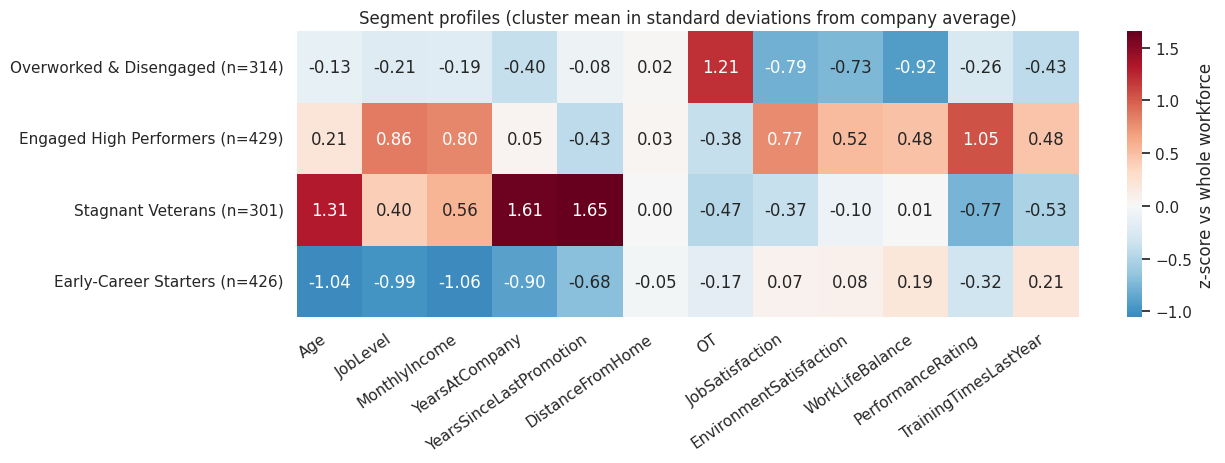

In [11]:
zs = ((prof[prof_cols] - df[prof_cols].mean()) / df[prof_cols].std()).copy(); zs.index = [f'{names[i]} (n={prof.Employees[i]})' for i in zs.index]
plt.figure(figsize=(13, 4.8)); sns.heatmap(zs, annot=True, fmt='.2f', cmap='RdBu_r', center=0, cbar_kws={'label': 'z-score vs whole workforce'})
plt.title('Segment profiles (cluster mean in standard deviations from company average)'); plt.xticks(rotation=35, ha='right'); plt.tight_layout()
plt.savefig('figures/06_segment_profile_heatmap.png', dpi=130); plt.show()

## 8. High-risk employee clusters

Company attrition: 16.1%
                         Employees  Leavers  Attrition_pct  Overtime_pct  Avg_JobSat  Avg_WLB  Lift_vs_company  Share_of_all_leavers_%
Segment                                                                                                                               
Overworked & Disengaged        314      135          42.99         90.13        1.94     1.84             2.68                    57.2
Early-Career Starters          426       61          14.32         25.12        2.75     2.86             0.89                    25.8
Stagnant Veterans              301       29           9.63         10.96        2.33     2.69             0.60                    12.3
Engaged High Performers        429       11           2.56         15.15        3.41     3.12             0.16                     4.7


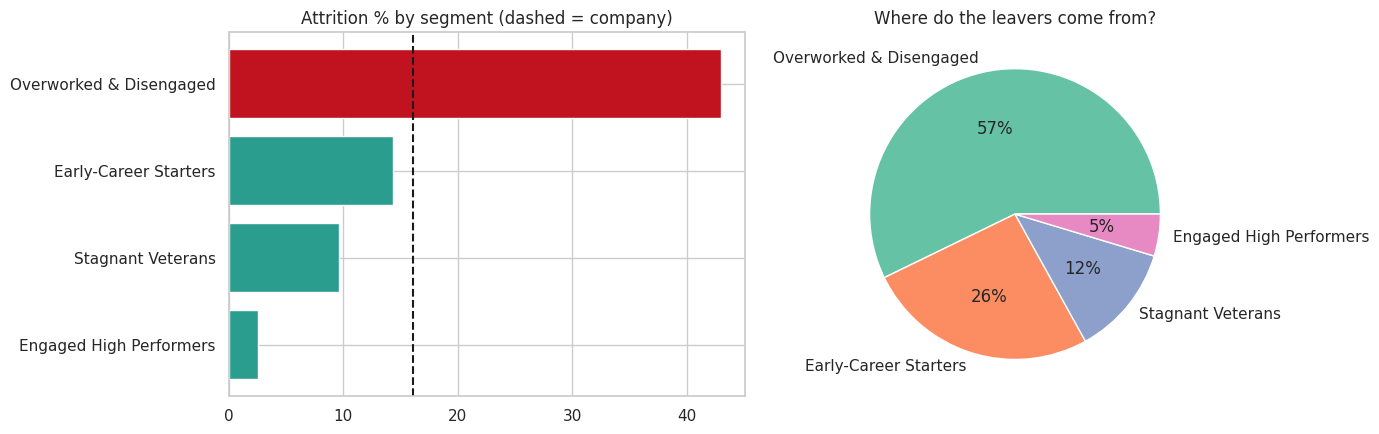

In [12]:
overall = df.Left.mean()*100
risk = df.groupby('Segment').agg(Employees=('Left','size'), Leavers=('Left','sum'), Attrition_pct=('Left', lambda s: 100*s.mean()),
                                 Overtime_pct=('OT', lambda s: 100*s.mean()), Avg_JobSat=('JobSatisfaction','mean'), Avg_WLB=('WorkLifeBalance','mean')).round(2)
risk['Lift_vs_company'] = (risk.Attrition_pct/overall).round(2)
risk['Share_of_all_leavers_%'] = (100*risk.Leavers/df.Left.sum()).round(1)
risk = risk.sort_values('Attrition_pct', ascending=False); print(f'Company attrition: {overall:.1f}%'); print(risk.to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
cols = ['#c1121f' if v > overall*1.25 else '#e07a1f' if v > overall*0.9 else '#2a9d8f' for v in risk.Attrition_pct]
ax[0].barh(risk.index, risk.Attrition_pct, color=cols); ax[0].axvline(overall, ls='--', color='k'); ax[0].set_title('Attrition % by segment (dashed = company)'); ax[0].invert_yaxis()
ax[1].pie(risk.Leavers, labels=risk.index, autopct='%1.0f%%', colors=sns.color_palette('Set2', len(risk))); ax[1].set_title('Where do the leavers come from?')
plt.tight_layout(); plt.savefig('figures/07_attrition_by_segment.png', dpi=130); plt.show()

## 9. Retention-risk groups

In [13]:
def tier(rate):
    return 'High risk' if rate >= overall*1.25 else ('Medium risk' if rate >= overall*0.85 else 'Low risk')
seg_tier = {s: tier(r) for s, r in risk.Attrition_pct.items()}
df['Retention_Tier'] = df.Segment.map(seg_tier)
# employee-level watch-list inside every segment: overtime + low satisfaction + low work-life balance
df['Watchlist'] = (df.OT == 1) & (df.JobSatisfaction <= 2) & (df.WorkLifeBalance <= 2)
tiers = df.groupby('Retention_Tier').agg(Employees=('Left','size'), Attrition_pct=('Left', lambda s: round(100*s.mean(), 1))).reindex(['High risk','Medium risk','Low risk']).dropna()
print('Segment-level retention tiers:'); print(pd.Series(seg_tier).to_string()); print(); print(tiers.to_string())
wl = df.groupby('Watchlist').agg(Employees=('Left','size'), Attrition_pct=('Left', lambda s: round(100*s.mean(), 1)))
print('\nEmployee-level watch-list (overtime + job satisfaction<=2 + work-life balance<=2):'); print(wl.to_string())
print('\nWatch-list members by segment:'); print(df[df.Watchlist].Segment.value_counts().to_string())

Segment-level retention tiers:
Overworked & Disengaged      High risk
Early-Career Starters      Medium risk
Stagnant Veterans             Low risk
Engaged High Performers       Low risk

                Employees  Attrition_pct
Retention_Tier                          
High risk             314           43.0
Medium risk           426           14.3
Low risk              730            5.5

Employee-level watch-list (overtime + job satisfaction<=2 + work-life balance<=2):
           Employees  Attrition_pct
Watchlist                          
False           1282           11.7
True             188           45.7

Watch-list members by segment:
Segment
Overworked & Disengaged    166
Early-Career Starters       10
Stagnant Veterans            8
Engaged High Performers      4


## 10. Department-level workforce segments

Segment mix inside each department (row %):
Segment                 Early-Career Starters  Engaged High Performers  Overworked & Disengaged  Stagnant Veterans
Department                                                                                                        
Human Resources                          20.3                     31.1                     25.7               23.0
Research & Development                   29.2                     30.3                     20.2               20.3
Sales                                    30.0                     26.3                     23.3               20.5

Headcount:
Segment                 Early-Career Starters  Engaged High Performers  Overworked & Disengaged  Stagnant Veterans
Department                                                                                                        
Human Resources                            15                       23                       19                 17
Research & Development  

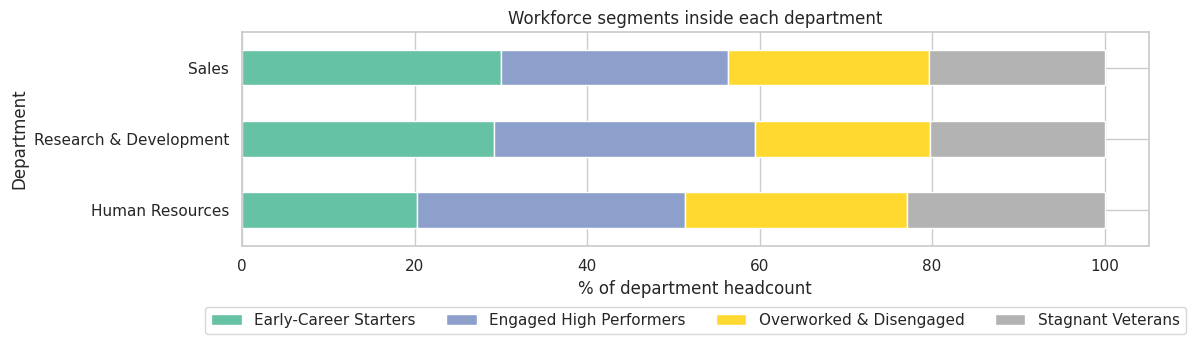

In [14]:
mix = pd.crosstab(df.Department, df.Segment, normalize='index').mul(100).round(1); cnt = pd.crosstab(df.Department, df.Segment)
print('Segment mix inside each department (row %):'); print(mix.to_string()); print('\nHeadcount:'); print(cnt.to_string())
dep_att = df.groupby('Department').Left.mean().mul(100).round(1); print('\nAttrition % by department:'); print(dep_att.to_string())
dxs = (df.groupby(['Department','Segment']).Left.agg(['size', lambda s: round(100*s.mean(), 1)]).rename(columns={'size':'n', '<lambda_0>':'Attrition_%'}))
print('\nAttrition % by department x segment (n shown; small cells are indicative only):'); print(dxs.to_string())
mix.plot(kind='barh', stacked=True, figsize=(12, 3.8), colormap='Set2'); plt.xlabel('% of department headcount'); plt.title('Workforce segments inside each department')
plt.legend(loc='upper center', bbox_to_anchor=(.5, -.25), ncol=4); plt.tight_layout(); plt.savefig('figures/08_department_segments.png', dpi=130); plt.show()

## 11. Performance groups
`PerformanceRating` is grouped into **Low (<= 2)**, **Solid (3)** and **High (>= 4)**. The key business question is *regretted attrition*: are our high performers leaving, and from which segment?

Performance-group mix per segment (row %):
PerfGroup                Low (<=2)  Solid (3)  High (>=4)
Segment                                                  
Early-Career Starters         27.5       61.0        11.5
Engaged High Performers        0.0       21.0        79.0
Overworked & Disengaged       27.7       54.8        17.5
Stagnant Veterans             54.8       45.2         0.0

Attrition by performance group:
            Employees  Attrition_pct
PerfGroup                           
Low (<=2)         369           17.1
Solid (3)         658           20.7
High (>=4)        443            8.4

Regretted attrition (high performers who left), by segment:
                         HighPerformers  Left  Attrition_pct
Segment                                                     
Overworked & Disengaged              55    23           41.8
Engaged High Performers             339     8            2.4
Early-Career Starters                49     6           12.2


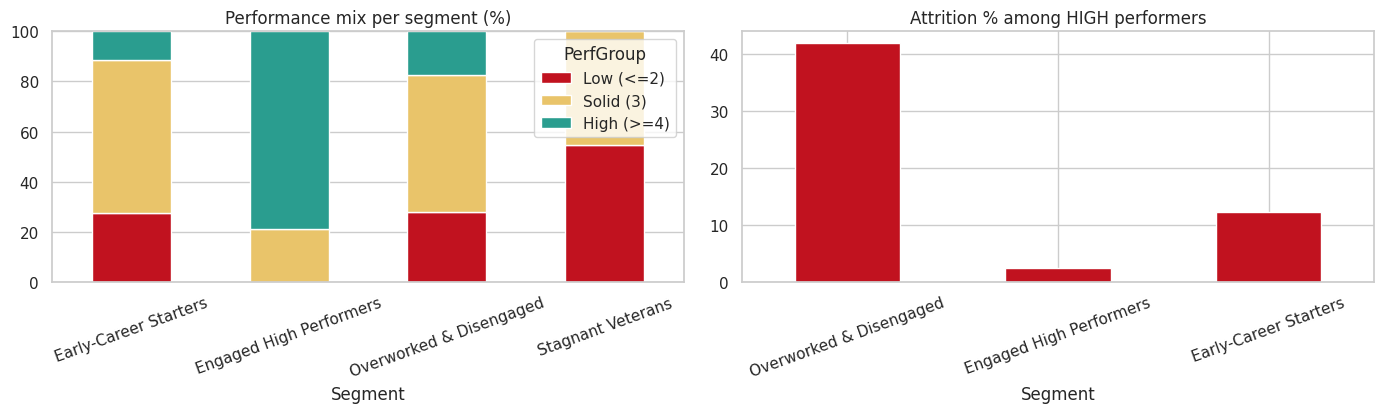

In [15]:
df['PerfGroup'] = pd.cut(df.PerformanceRating, [0, 2, 3, 5], labels=['Low (<=2)', 'Solid (3)', 'High (>=4)'])
pm = pd.crosstab(df.Segment, df.PerfGroup, normalize='index').mul(100).round(1); print('Performance-group mix per segment (row %):'); print(pm.to_string())
pa = df.groupby('PerfGroup', observed=True).agg(Employees=('Left','size'), Attrition_pct=('Left', lambda s: round(100*s.mean(), 1))); print('\nAttrition by performance group:'); print(pa.to_string())
reg = df[df.PerfGroup == 'High (>=4)'].groupby('Segment').agg(HighPerformers=('Left','size'), Left=('Left','sum'), Attrition_pct=('Left', lambda s: round(100*s.mean(), 1))).sort_values('Left', ascending=False)
print('\nRegretted attrition (high performers who left), by segment:'); print(reg.to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
pm.plot(kind='bar', stacked=True, ax=ax[0], color=['#c1121f', '#e9c46a', '#2a9d8f']); ax[0].set_title('Performance mix per segment (%)'); ax[0].tick_params(axis='x', rotation=20)
reg.Attrition_pct.plot(kind='bar', ax=ax[1], color='#c1121f'); ax[1].set_title('Attrition % among HIGH performers'); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig('figures/09_performance_groups.png', dpi=130); plt.show()

## 12. Export for the report and dashboard

In [16]:
pc_total = pca_full.explained_variance_ratio_.cumsum()
out_cols = ['EmployeeID','Department','Segment','Retention_Tier','PerfGroup','Watchlist','Attrition','PC1','PC2']
df[out_cols].round(3).to_csv('outputs/employee_segments.csv', index=False)
prof.round(3).to_csv('outputs/segment_profile.csv'); pca_table.to_csv('outputs/pca_summary.csv', index=False); load.round(3).to_csv('outputs/pca_loadings_top4.csv')
payload = {
  'overall': {'employees': int(len(df)), 'attrition_pct': round(overall, 1), 'k': K, 'n_pc': N_PC, 'variance_retained_pct': round(100*pca.explained_variance_ratio_.sum(), 1),
              'silhouette_kmeans': round(float(cmp.loc['K-Means','Silhouette']), 3), 'silhouette_hc': round(float(cmp.loc['Hierarchical (Ward)','Silhouette']), 3), 'ari_km_hc': round(float(ari), 3)},
  'pca': {'evr_pct': [round(float(v)*100, 2) for v in evr], 'cum_pct': [round(float(v)*100, 2) for v in pc_total]},
  'segments': [{'name': s, 'employees': int(risk.loc[s,'Employees']), 'attrition_pct': float(risk.loc[s,'Attrition_pct']), 'overtime_pct': float(risk.loc[s,'Overtime_pct']),
                'tier': seg_tier[s], 'job_sat': float(risk.loc[s,'Avg_JobSat']), 'wlb': float(risk.loc[s,'Avg_WLB']),
                'age': round(float(df[df.Segment==s].Age.mean()), 1), 'tenure': round(float(df[df.Segment==s].YearsAtCompany.mean()), 1),
                'income': int(df[df.Segment==s].MonthlyIncome.mean()), 'since_promo': round(float(df[df.Segment==s].YearsSinceLastPromotion.mean()), 1),
                'perf': round(float(df[df.Segment==s].PerformanceRating.mean()), 2)} for s in risk.index],
  'dept_mix': {d: {s: float(mix.loc[d, s]) for s in mix.columns} for d in mix.index},
  'dept_attrition': {d: float(v) for d, v in dep_att.items()},
  'perf_mix': {s: {p: float(pm.loc[s, p]) for p in pm.columns} for s in pm.index},
  'high_perf_attrition': {s: float(v) for s, v in reg.Attrition_pct.items()},
  'watchlist': {'employees': int(df.Watchlist.sum()), 'attrition_pct': float(wl.loc[True, 'Attrition_pct'])},
  'points': [[round(float(a), 2), round(float(b), 2), s, int(l)] for a, b, s, l in zip(df.PC1, df.PC2, df.Segment, df.Left)][::2]}
json.dump(payload, open('outputs/dashboard_data.json', 'w')); print('Saved: employee_segments.csv, segment_profile.csv, pca_summary.csv, pca_loadings_top4.csv, dashboard_data.json')

Saved: employee_segments.csv, segment_profile.csv, pca_summary.csv, pca_loadings_top4.csv, dashboard_data.json


## 13. Key findings (computed from the results above)

In [17]:
hi = risk.index[0]; r = risk.loc[hi]
print(f'1. {K} workforce segments were found; K-Means and Hierarchical agree (ARI = {ari:.2f}); PCA keeps {100*pca.explained_variance_ratio_.sum():.0f}% of the variance in {N_PC} components.')
print(f'2. Highest-risk cluster: "{hi}" - {r.Attrition_pct:.1f}% attrition ({r.Lift_vs_company:.1f}x company average), {r.Overtime_pct:.0f}% on overtime, {r["Share_of_all_leavers_%"]:.0f}% of all leavers.')
lo = risk.index[-1]; print(f'3. Lowest-risk cluster: "{lo}" - {risk.loc[lo,"Attrition_pct"]:.1f}% attrition.')
print(f'4. Watch-list (overtime + low satisfaction + low work-life balance): {int(df.Watchlist.sum())} employees leave at {wl.loc[True,"Attrition_pct"]:.1f}% vs {wl.loc[False,"Attrition_pct"]:.1f}% for everyone else.')
print(f'5. Highest-attrition department: {dep_att.idxmax()} ({dep_att.max():.1f}%); lowest: {dep_att.idxmin()} ({dep_att.min():.1f}%).')
print(f'6. Segment with most regretted attrition (high performers who left): {reg.index[0]} ({int(reg.Left.iloc[0])} people).')

1. 4 workforce segments were found; K-Means and Hierarchical agree (ARI = 0.74); PCA keeps 86% of the variance in 7 components.
2. Highest-risk cluster: "Overworked & Disengaged" - 43.0% attrition (2.7x company average), 90% on overtime, 57% of all leavers.
3. Lowest-risk cluster: "Engaged High Performers" - 2.6% attrition.
4. Watch-list (overtime + low satisfaction + low work-life balance): 188 employees leave at 45.7% vs 11.7% for everyone else.
5. Highest-attrition department: Sales (17.7%); lowest: Research & Development (15.2%).
6. Segment with most regretted attrition (high performers who left): Overworked & Disengaged (23 people).
